# Newton Time Series Workshop

**Archetype AI · Newton**

In this workshop you call Newton, Archetype AI's physical world model, from Python to work out what a system or group of systems is doing from its sensor readings. Starting from a CSV file of your sensor measurements, you build, step by step:

1. a plot of the raw signal, cut into **windows** (short, equal-length slices of the recording),
2. a **Newton embedding** for each window: a list of numbers, returned by Newton, that summarises how the signal behaves in that window. Windows that behave alike get similar numbers,
3. a 2-D map of the embeddings, where the machine's different states show up as separate groups,
4. a classifier that learns to name the machine's state from a handful of labelled windows,
5. a state timeline for the whole recording.

Libraries: `archetypeai` (the official client), `numpy` for arrays, `pandas` to read the CSV, `matplotlib` to draw, `scikit-learn` for the map.

| | |
|---|---|
| Time | 90 minutes |
| Level | comfortable with Python; no signal-processing background needed |
| Runs on | Google Colab (recommended) or any Python 3.10+ environment |
| Based on | the Newton time-series examples in [archetypeai/agent-skills](https://github.com/archetypeai/agent-skills/tree/main/skills/atai-newton-omega-model) and the [Developer Quickstart](https://docs.archetypeai.app/introduction/getting-started) |

Run the cells in order. Cells marked **Exercise** are yours to write; each has a hint and a **Checkpoint** that says what a correct result looks like.

## 0. Before you start: your API key

Newton is called with a personal API key. To create one:

1. Open **https://platform.u1.archetypeai.app/console/profile** and log in with the email address your invitation was sent to (reset the temporary password first if you received one).
2. On **Profile & API Keys**, click **Create API key**, name it, and copy the key. It is shown once.
3. The key bills to your organisation: keep it out of repositories and shared documents.

No account yet? Request one at https://www.archetypeai.io/try-newton. Documentation: https://docs.archetypeai.app.

The endpoint is the same for everyone: `https://platform.u1.archetypeai.app`.

## 1. Setup

Install the Archetype AI client and the four helper libraries.

In [1]:
%pip install -q archetypeai numpy pandas matplotlib scikit-learn

Now give the notebook your key by pasting it between the quotes in the cell below. If you leave the quotes empty, the cell asks for the key with a hidden prompt, so the key never appears in the notebook output.

A pasted key is saved with the notebook: **clear it before you share the file.**

In [2]:
import os, getpass

ATAI_API_KEY = ""   # <-- paste your API key here, or leave empty to use the exported key or be prompted
ATAI_API_ENDPOINT = "https://platform.u1.archetypeai.app"

if not ATAI_API_KEY:
    ATAI_API_KEY = os.environ.get("ATAI_API_KEY") or getpass.getpass("Archetype AI API key: ")
assert ATAI_API_KEY, "An API key is required (section 0 explains how to get one)."
print("Key loaded:", ATAI_API_KEY[:2] + "..." + ATAI_API_KEY[-4:])

### Sending a request to Newton

We'll now send an HTTP request to the Archetype AI platform to get a Newton timeseries embedding. Each request requires a **model** id and one **event** holding the numbers of a single window. The numbers are arranged as one list per **channel** (a channel is the stream of readings from one sensor), and a window is 16 to 1024 readings long, in a multiple of 16. For every request, Newton returns one 768-d embedding for each channel.

The helper below wraps that request so the rest of the notebook reads `embed(window)`. The first call sends a made-up signal, a sine wave, so you can check the connection before loading any data.

In [3]:
import json, time
import numpy as np
from archetypeai.api_client import ArchetypeAI

MODEL = "OmegaEncoder::omega_embeddings_1_4"     # the id of Newton's time-series model
client = ArchetypeAI(ATAI_API_KEY, api_endpoint=ATAI_API_ENDPOINT.rstrip("/") + "/api")

def embed(window):
    """One call to Newton: one window of sensor readings in, its embedding out.
    window:   16 to 1024 readings, in a multiple of 16. A 1-D array is one channel; a 2-D array is [channels x readings], one row per sensor.
    returns:  a NumPy array of shape [channels x 768]: one embedding (768 numbers) per channel."""
    contents = np.atleast_2d(np.asarray(window, dtype=float))    # the API wants one row per channel, even for a single channel
    length = contents.shape[1]
    if not 16 <= length <= 1024 or length % 16 != 0:
        raise ValueError(f"A window must be a multiple of 16 readings long, from 16 to 1024; this one has {length}.")
    body = {"model": MODEL,
            "query": "",                  # the time-series model takes no question, so the query stays empty
            "normalize_input": False,     # send the readings as they are, without rescaling them
            "events": [{"type": "data.numeric_array", "event_data": {"contents": contents.tolist()}}]}
    payload = client.requests_post(f"{client.api_endpoint}/lens/query", data_payload=json.dumps(body),
                                   additional_headers={"Content-Type": "application/json"})
    return np.atleast_2d(payload["response"]["response"])        # a single channel comes back as a flat list: make it a row too

t = np.arange(1024) / 1024               # 1024 time steps
wave = np.sin(2 * np.pi * 5 * t)         # a made-up signal: a sine wave that repeats 5 times

t0 = time.time()
embedding = embed(wave)
print(f"[{time.time() - t0:.1f}s] embedding shape: {embedding.shape}, first values: {np.round(embedding[0, :4], 3)}")

[1.7s] embedding shape: (1, 768), first values: [ 0.882 -0.126 -0.055  0.009]


**Checkpoint.** You should see the shape `(1, 768)` after about a second: one channel went in, and one embedding of 768 numbers came back. An error containing `unauthorized` means the key is wrong. An empty error, `ApiError: {}`, means the endpoint URL is wrong (it must be `https://platform.u1.archetypeai.app`, nothing after it).

## 2. The sample data

The initial sample dataset we will use is drilling log data from the Volve oil field in the North Sea. The dataset contains 2,750 readings from nine sensors on a drilling rig. Readings are sampled every 5 seconds and there are 3.8 hours in all. A second file gives the rig's **state** at each reading, taken from the rig's own activity log: `shut_in`, `off_bottom`, `drilling`, `reaming` or `trip_in_slips`. Our goal is to use Newton embeddings to create an agent that can detect when the rig is in one of these states.

| Channel | What it measures | Unit |
|---|---|---|
| `BPOS` | Block position: height of the travelling block | m |
| `DBTM` | Bit depth: how deep the drill bit is | m |
| `FLWI` | Flow in: mud flow rate into the hole | L/min |
| `HDTH` | Hole depth: total depth of the hole | m |
| `HKLD` | Hookload: weight hanging from the hook | kkgf (thousand kilograms-force) |
| `ROP` | Rate of penetration: drilling speed | m/h |
| `RPM` | Rotary speed: rotation of the drill string | rpm |
| `SPPA` | Standpipe pressure: mud pump pressure | kPa |
| `WOB` | Weight on bit: downward force on the rock | kkgf |

The log is six stretches of the original recording joined end to end, so the state changes abruptly from one stretch to the next.

The data comes from the [Volve field dataset](https://www.equinor.com/energy/volve-data-sharing), disclosed by Equinor and its Volve licence partners for research, study and development, and is used under the Equinor Open Data Licence. Archetype AI prepared this sample for its [examples](https://github.com/archetypeai/agent-skills/tree/main/skills/atai-operational-state-monitoring-agent/references/sample_data).

In [4]:
# Load the sample dataset
import urllib.request, pathlib
import pandas as pd

DATA = "https://raw.githubusercontent.com/archetypeai/agent-skills/main/skills/atai-operational-state-monitoring-agent/references/sample_data/"
for name in ["drilling_volve_f14.csv", "drilling_volve_f14_labels.csv"]:
    if not pathlib.Path(name).exists():
        urllib.request.urlretrieve(DATA + name, name)
    print(f"{name:30s} {pathlib.Path(name).stat().st_size / 1e3:.0f} kB")

log = pd.read_csv("drilling_volve_f14.csv")                                 # one row per reading: a timestamp and nine sensor channels
state = pd.read_csv("drilling_volve_f14_labels.csv")["label"].to_numpy()    # the rig's logged state at each reading
CHANNELS = [c for c in log.columns if c != "timestamp"]
minutes = (log["timestamp"] - log["timestamp"].iloc[0]).to_numpy() / 60     # time since the start of the recording
print(f"{len(log)} readings, {len(CHANNELS)} channels, {minutes[-1] / 60:.1f} hours")
log.head()

drilling_volve_f14.csv         336 kB
drilling_volve_f14_labels.csv  58 kB
2750 readings, 9 channels, 3.8 hours


,timestamp,BPOS,DBTM,FLWI,HDTH,HKLD,ROP,RPM,SPPA,WOB
0,1194200000,9.15,194.460007,0.0,203.990005,63.018461,15.51,0.0,138.000001,0.0
1,1194200005,9.15,194.460007,0.0,203.990005,62.906292,15.51,0.0,119.000008,0.0
2,1194200010,9.15,194.460007,0.0,203.990005,62.947082,15.51,0.0,116.999998,0.0
3,1194200015,9.15,194.460007,0.0,203.990005,62.875702,15.51,0.0,120.000003,0.0
4,1194200020,9.31,194.460007,0.0,203.990005,62.783927,15.51,0.0,119.000008,0.0


Plot the nine channels over time. The coloured strip on top is the rig's logged state at each moment.

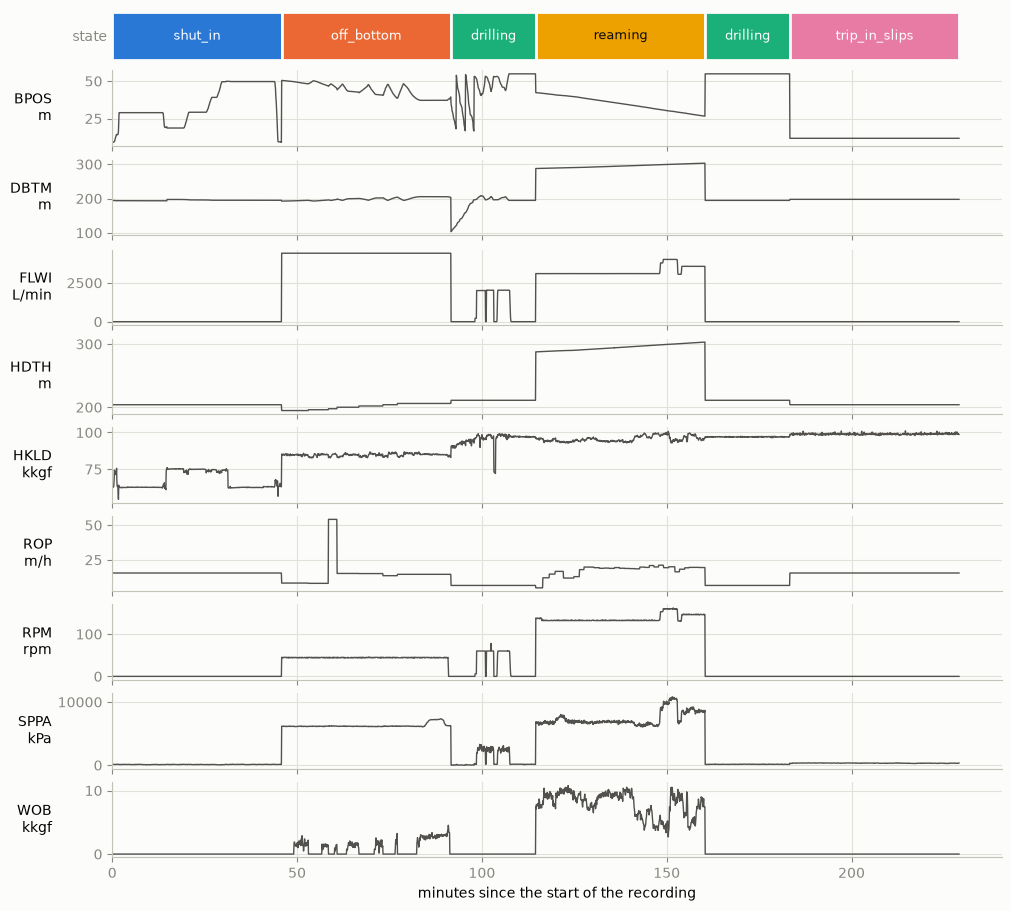

In [5]:
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7", "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": "#e1e0d9", "xtick.color": "#898781", "ytick.color": "#898781"})

UNITS = {"BPOS": "m", "DBTM": "m", "FLWI": "L/min", "HDTH": "m", "HKLD": "kkgf", "ROP": "m/h", "RPM": "rpm", "SPPA": "kPa", "WOB": "kkgf"}
STATE_COLORS = {"shut_in": "#2a78d6", "off_bottom": "#eb6834", "drilling": "#1baf7a", "reaming": "#eda100", "trip_in_slips": "#e87ba4"}

def state_runs(labels):
    """Consecutive stretches of one state, as (state, first index, index after the last)."""
    edges = np.flatnonzero(labels[1:] != labels[:-1]) + 1
    bounds = np.concatenate([[0], edges, [len(labels)]])
    return [(labels[a], a, b) for a, b in zip(bounds[:-1], bounds[1:])]

def draw_states(ax, labels, x, name="state"):
    """Draw a sequence of states as a strip of coloured blocks, one block per stretch of the same state."""
    step = x[1] - x[0]
    for s, a, b in state_runs(labels):
        ax.barh(0, (b - a) * step, left=x[a], align="center", color=STATE_COLORS[s], edgecolor="#fcfcfb", linewidth=2)
        if (b - a) * step > 0.08 * (x[-1] - x[0]):          # write the name only where the block is wide enough to hold it
            ax.text(x[a] + (b - a) * step / 2, 0, s, ha="center", va="center", fontsize=9, color="#0b0b0b" if s == "reaming" else "white")
    ax.set_yticks([0], [name]); ax.grid(False); ax.spines[["left", "bottom"]].set_visible(False); ax.tick_params(length=0)

fig, axes = plt.subplots(len(CHANNELS) + 1, 1, figsize=(10, 9), sharex=True, height_ratios=[0.7] + [1] * len(CHANNELS), layout="constrained")
draw_states(axes[0], state, minutes)
for ax, name in zip(axes[1:], CHANNELS):
    ax.plot(minutes, log[name], color="#52514e", linewidth=1)
    ax.set_ylabel(f"{name}\n{UNITS[name]}", rotation=0, ha="right", va="center")
axes[-1].set_xlabel("minutes since the start of the recording")
fig.align_ylabels(); plt.show()

## 3. Lab 1: cut the recording into windows

Newton reads one window at a time, so the recording has to be cut into windows first. Here a window is 32 readings, which is 160 seconds; Newton needs the length to be a multiple of 16. Each window is given one state: the state that most of its readings have.

windows: (85, 9, 32) = [windows x channels x readings]
drilling         18
shut_in          17
off_bottom       17
reaming          17
trip_in_slips    16


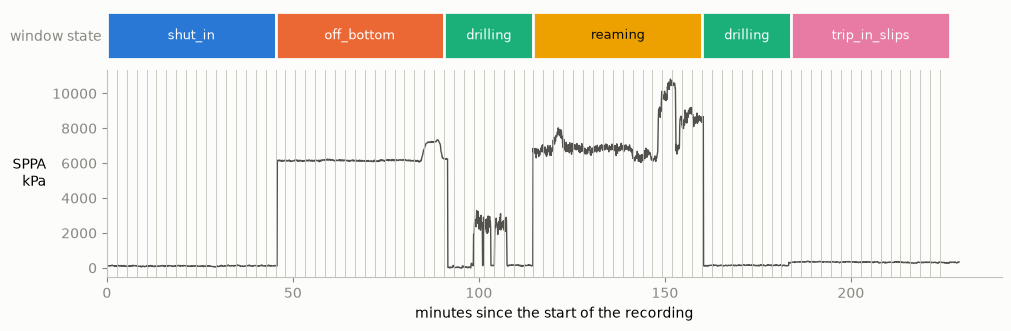

In [6]:
def cut(size, overlap=0.0):
    """Cut the recording into windows of `size` readings.
    overlap: the share of a window that the next window repeats. 0 puts the windows end to end; 0.5 starts each one halfway through the one before.
    Returns the windows as [windows x channels x readings], one state per window (the state most of its readings have),
    and the reading each window starts at."""
    step = max(1, round(size * (1 - overlap)))                # readings from the start of one window to the start of the next
    starts = np.arange(0, len(log) - size + 1, step)          # a window that would run past the end of the recording is left out
    values = log[CHANNELS].to_numpy()                         # [readings x channels]
    windows = np.stack([values[s:s + size].T for s in starts])
    window_state = np.array([pd.Series(state[s:s + size]).mode()[0] for s in starts])
    return windows, window_state, starts

WINDOW = 32                                                   # readings per window, a multiple of 16: 32 readings x 5 s = 160 s
OVERLAP = 0.0                                                 # the share of a window that the next one repeats: 0 = none
windows, window_state, window_start = cut(WINDOW, OVERLAP)
print("windows:", windows.shape, "= [windows x channels x readings]")
print(pd.Series(window_state).value_counts().to_string())

# One channel with the start of each window drawn in, and the state given to each window on top.
fig, (top, ax) = plt.subplots(2, 1, figsize=(10, 3.2), sharex=True, height_ratios=[0.25, 1], layout="constrained")
draw_states(top, window_state, minutes[window_start], "window state")
ax.plot(minutes, log["SPPA"], color="#52514e", linewidth=1)
for edge in minutes[window_start]:
    ax.axvline(edge, color="#c3c2b7", linewidth=0.6)
ax.grid(False); ax.set_ylabel("SPPA\nkPa", rotation=0, ha="right", va="center"); ax.set_xlabel("minutes since the start of the recording")
plt.show()

### Exercise 1.1: how long should a window be?

A window that spans a change of state is **mixed**: it belongs cleanly to neither state. Count the mixed windows for four window lengths: 16, 32, 64 and 128 readings.

In [7]:
for size in (16, 32, 64, 128):
    n = len(log) // size                                                              # whole windows that fit
    mixed = sum(len(set(state[i * size:(i + 1) * size])) > 1 for i in range(n))       # windows that hold more than one state
    print(f"{size:4d} readings: {n:4d} windows, {mixed} mixed")

  16 readings:  171 windows, 5 mixed
  32 readings:   85 windows, 5 mixed
  64 readings:   42 windows, 5 mixed
 128 readings:   21 windows, 5 mixed


**Checkpoint.** Every length gives 5 mixed windows: one for each change of state in the recording. What changes is the share they make up: 5 of 171 windows at 16 readings, 5 of 85 at 32, 5 of 21 at 128. A longer window shows Newton more of the signal, but leaves you fewer windows, and more of them unclear.

### Overlap: how far apart the windows start

`cut` has a second setting. With `overlap=0` the windows sit end to end, and every reading belongs to exactly one window. With an overlap, each window starts before the one before it has ended: at `0.5` halfway through it, at `0.75` a quarter of the way through.

Window length and overlap together decide what Newton is shown and how often, so they shape everything that comes out of it:

- **How many Newton embeddings you get.** Overlap multiplies the windows: twice as many at 0.5, four times as many at 0.75. Each window is one request, so the time and the cost multiply with it.
- **How often you get an answer.** Each window gets one state, so with no overlap there is a new answer every 160 seconds, and at 0.75 every 40 seconds. A change of state shows up sooner.
- **How much is new in each window.** Overlapping windows share most of their readings, so their Newton embeddings are nearly the same. Four times the windows is not four times the information.

The next cell cuts the same recording at three overlaps.

 overlap  windows  a new window every  mixed windows
      0%       85               160 s              5
     50%      170                80 s             10
     75%      340                40 s             19


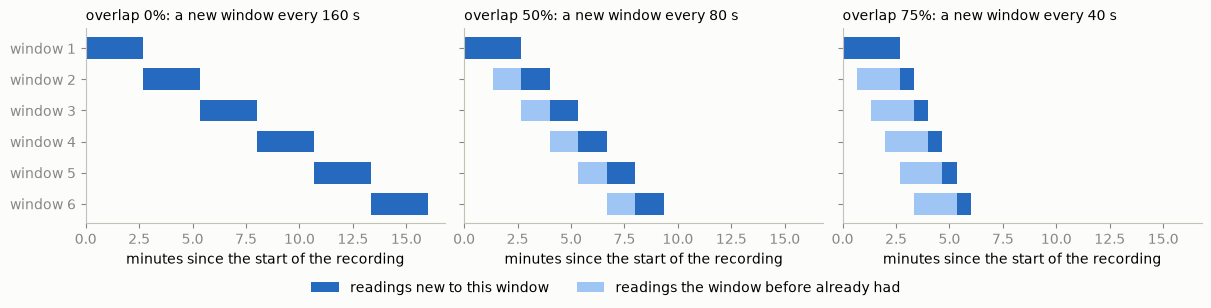

In [8]:
OVERLAPS = (0.0, 0.5, 0.75)
print(f"{'overlap':>8} {'windows':>8} {'a new window every':>19} {'mixed windows':>14}")
for overlap in OVERLAPS:
    w, _, start = cut(WINDOW, overlap)
    mixed = sum(len(set(state[s:s + WINDOW])) > 1 for s in start)
    print(f"{overlap:8.0%} {len(w):8d} {(start[1] - start[0]) * 5:17d} s {mixed:14d}")

# The first six windows at each overlap, one row per window, in the order they are cut.
# The pale part of a bar is readings that the window before it already had.
fig, axes = plt.subplots(1, len(OVERLAPS), figsize=(12, 3), sharex=True, sharey=True, layout="constrained")
for ax, overlap in zip(axes, OVERLAPS):
    _, _, start = cut(WINDOW, overlap)
    length, step = WINDOW * 5 / 60, (start[1] - start[0]) * 5 / 60          # a window's length, and the wait before the next one starts, in minutes
    for k in range(6):
        ax.barh(k, length, left=k * step, height=0.7, color="#256abf", label="readings new to this window" if k == 0 else None)
        if k > 0 and overlap > 0:
            ax.barh(k, length - step, left=k * step, height=0.7, color="#9ec5f4", label="readings the window before already had" if k == 1 else None)
    ax.set_title(f"overlap {overlap:.0%}: a new window every {step * 60:.0f} s", loc="left", fontsize=10)
    ax.set_xlabel("minutes since the start of the recording"); ax.grid(False)
axes[0].set_yticks(range(6), [f"window {k + 1}" for k in range(6)]); axes[0].invert_yaxis()
fig.legend(*axes[1].get_legend_handles_labels(), loc="outside lower center", ncols=2, frameon=False)
plt.show()

**Checkpoint.** You should see 85, 170 and 340 windows, with a new one every 160, 80 and 40 seconds. In the figure each row is one window, in the order they are cut. With no overlap, each window starts where the one before it ended. With an overlap, each window starts before the one before it has ended, and the pale part of its bar is the readings it shares with that earlier window: half of the bar at 50%, three quarters at 75%. The mixed windows multiply too (5, 10, 19), because more windows now straddle each change of state.

The notebook carries on with `OVERLAP = 0.0`, the cheapest setting. To try another, change `OVERLAP` in the cell where the windows are cut and rerun from there.

## 4. Lab 2: scale the windows

Look back at the y-axes of the first plot: standpipe pressure (`SPPA`) runs to about 10,000 kPa, weight on bit (`WOB`) to about 10 kkgf. Those sizes come from the units, not from what the rig is doing, and Newton reads the numbers as they are. So before embedding, every channel is put on a common scale with a **z-score**: subtract a centre (the mean) and divide by a spread (the standard deviation). The values then sit around 0 with a spread of about 1, whatever the unit was.

The choice that matters is where the centre and spread are measured:

| `SCALING` | Centre and spread are measured over | What a window keeps |
|---|---|---|
| `"recording"` | the whole recording, once per channel | its shape and its **level** relative to the other windows: a window with the pumps running still has larger numbers than one with the pumps off |
| `"window"` | each window on its own | its shape only: every window ends up centred on 0, so the difference in level between windows is gone |

Neither is always right. When states differ in how high or low the readings are, as pumps on and pumps off do, keep the level and use `"recording"`. When only the pattern inside a window matters and the level drifts for reasons you want to ignore (a sensor that warms up, a second machine of the same model), `"window"` removes that drift.

The next cell defines both, and a switch: `SCALING`. Every later lab uses the windows it produces, so to compare the two, change `SCALING` and rerun the notebook from that cell down.

Newton can also do the per-window version itself, with `"normalize_input": True` in the request. `embed` sets it to `False`, so the scaling happens here, where you can see it and choose it.

SCALING = "recording": scaled windows (85, 9, 32)


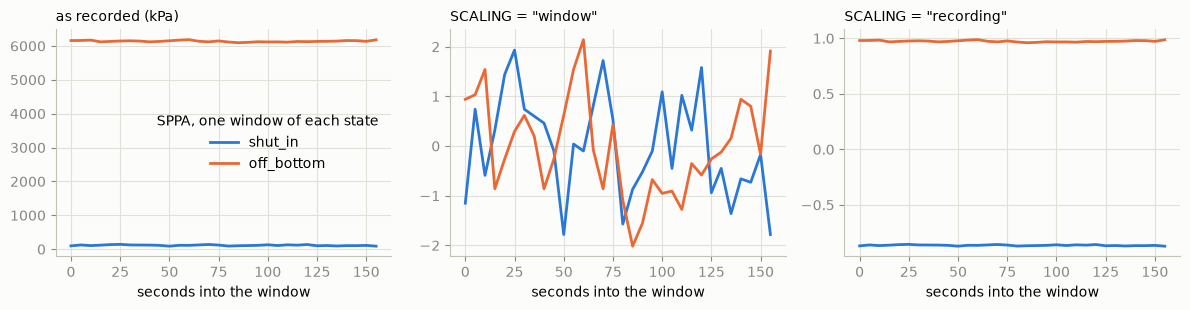

In [9]:
def scale(windows, how):
    """Put every channel on a common scale: subtract a centre, then divide by a spread.
    how="recording": one centre and spread per channel, measured over all the windows. A window keeps its level relative to the others.
    how="window":    each window is measured on its own. A window keeps only its shape."""
    over = {"recording": (0, 2), "window": 2}[how]                      # the axes to measure over: every window and reading, or one window's readings
    centre = windows.mean(axis=over, keepdims=True)
    spread = windows.std(axis=over, keepdims=True)
    return (windows - centre) / np.where(spread > 1e-9, spread, 1)      # a channel that does not change has no spread to divide by: leave it at 0

SCALING = "recording"                         # <-- the switch: "recording" or "window"
scaled = scale(windows, SCALING)              # the rest of the notebook embeds `scaled`
print(f'SCALING = "{SCALING}": scaled windows {scaled.shape}')

# The same two windows of one channel, seen three ways.
channel, quiet, busy = "SPPA", "shut_in", "off_bottom"
picks = {s: np.flatnonzero(window_state == s)[1] for s in (quiet, busy)}        # the second window of each state
seconds = np.arange(WINDOW) * 5
views = {f"as recorded ({UNITS[channel]})": windows, 'SCALING = "window"': scale(windows, "window"), 'SCALING = "recording"': scale(windows, "recording")}
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, (title, data) in zip(axes, views.items()):
    for s, i in picks.items():
        ax.plot(seconds, data[i, CHANNELS.index(channel)], color=STATE_COLORS[s], linewidth=2, label=s)
    ax.set_title(title, loc="left", fontsize=10); ax.set_xlabel("seconds into the window")
axes[0].legend(frameon=False, title=f"{channel}, one window of each state")
plt.tight_layout(); plt.show()

**Checkpoint.** The left panel shows standpipe pressure in one `shut_in` window and one `off_bottom` window as recorded: about 6,000 kPa apart. With `"window"` scaling (middle) the two cannot be told apart: both wobble around 0, and the small ripples in the quiet window have been stretched to the same size as everything else. With `"recording"` scaling (right) they stay apart, now measured in spreads instead of kPa.

### Exercise 2.1: how much does per-window scaling remove?

Put a number on what the figure shows. A window's **level** on a channel is the mean of its readings. For each channel, measure how much the level varies from one window to the next, under each scaling.

In [10]:
for how in ("recording", "window"):
    levels = scale(windows, how).mean(axis=2)          # [windows x channels]: each window's level on each channel
    share = levels.var(axis=0)                         # how much the level varies between windows, per channel
    print(f"{how:10s}", dict(zip(CHANNELS, share.round(2).tolist())))

recording  {'BPOS': 0.92, 'DBTM': 0.97, 'FLWI': 0.96, 'HDTH': 0.99, 'HKLD': 0.98, 'ROP': 0.85, 'RPM': 0.97, 'SPPA': 0.96, 'WOB': 0.96}
window     {'BPOS': 0.0, 'DBTM': 0.0, 'FLWI': 0.0, 'HDTH': 0.0, 'HKLD': 0.0, 'ROP': 0.0, 'RPM': 0.0, 'SPPA': 0.0, 'WOB': 0.0}


**Checkpoint.** With `"recording"` scaling, every channel comes out at 0.85 or more, and eight of the nine above 0.9. After this scaling each channel's variance over the whole recording is 1, so these numbers are shares: almost all of what these sensors say is which level they are at, not how they move inside a window. With `"window"` scaling every channel comes out at 0: that information is gone. For this recording, leave `SCALING = "recording"`.

## 5. Lab 3: a Newton embedding for every window

Now each window goes to Newton. `embed` returns one embedding of 768 numbers per channel, so a window of nine channels comes back as 9 × 768 numbers. Joined end to end, they make one vector of 6,912 numbers that describes the whole window: what all nine sensors were doing during those 160 seconds.

There are 85 windows, so 85 requests. One at a time, that takes about a minute and a half. The requests do not depend on each other, so the cell below sends 8 at a time and finishes in about half a minute.

In [11]:
from concurrent.futures import ThreadPoolExecutor

def embed_all(windows, workers=8):
    """A Newton embedding for every window: [windows x channels x readings] in, [windows x channels x 768] out.
    The requests do not depend on each other, so `workers` of them are sent at the same time."""
    with ThreadPoolExecutor(workers) as pool:
        return np.stack(list(pool.map(embed, windows)))

def to_vectors(embeddings):
    """One vector per window: its channel embeddings joined end to end, then scaled to length 1 so that only the direction counts."""
    joined = embeddings.reshape(len(embeddings), -1)
    return joined / np.linalg.norm(joined, axis=1, keepdims=True)

t0 = time.time()
embeddings = embed_all(scaled)
vectors = to_vectors(embeddings)
print(f"[{time.time() - t0:.0f}s] embeddings: {embeddings.shape} = [windows x channels x 768]")
print(f"vectors:    {vectors.shape} = [windows x {len(CHANNELS)} channels * 768]")

[32s] embeddings: (85, 9, 768) = [windows x channels x 768]
vectors:    (85, 6912) = [windows x 9 channels * 768]


**Checkpoint.** `embeddings` has the shape `(85, 9, 768)` and `vectors` has `(85, 6912)`: one row per window.

### How alike are two windows?

A vector of 6,912 numbers says little on its own. What it is good for is comparison. The **cosine similarity** of two vectors measures whether they point the same way: 1 means the same direction, and the lower the number, the less alike the two windows are. Because every vector here has length 1, the similarity of two vectors is simply the sum of the products of their numbers.

### Exercise 3.1: compare every window with every other

The function `show_similarity` in the next cell draws the comparison as a square picture. Each row and each column is one window, in the order of the recording, and the darker a cell, the more alike its two windows are. The function also prints two averages: the similarity of windows that have the same state, and of windows that do not.

The drawing is written for you. The first four lines of the function are missing, and they are yours to write. They have to make these:

| Name | What it holds |
|---|---|
| `similarity` | how alike each pair of windows is: one number per pair |
| `same_state` | whether each pair of windows has the same state: `True` or `False` per pair |
| `not_itself` | `False` where a window is paired with itself, `True` for every other pair |
| `within`, `between` | the average similarity of the pairs with the same state, and of the pairs with different states |

The first three are square tables with one row and one column per window, 85 by 85. The cell in row `i` and column `j` is about window `i` and window `j` together.

`same_state` and `not_itself` are **masks**: tables of `True` and `False` used to pick cells out of another table. `similarity[mask]` keeps the numbers where the mask is `True`, and `.mean()` averages them.

`not_itself` is needed because a window compared with itself always scores 1, and always has its own state. Left in, those 85 perfect scores would flatter the average within a state.

Each of the four lines is one NumPy expression. The comments in the cell say what each line should make, how, and with which tools.

SCALING = "recording": average similarity within a state 0.94, between states 0.70


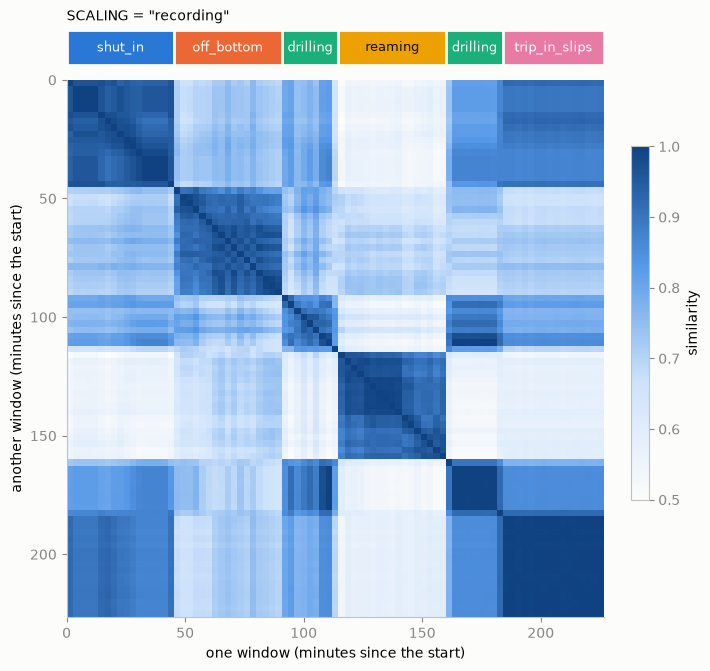

In [12]:
from matplotlib.colors import LinearSegmentedColormap
BLUES = LinearSegmentedColormap.from_list("blues", ["#fcfcfb", "#cde2fb", "#5598e7", "#104281"])      # light = different, dark = alike

def show_similarity(vectors, title):
    """Compare every window with every other, print the average similarity within a state and between states, and draw the comparison."""

    similarity = vectors @ vectors.T                                    # [windows x windows]; for vectors of length 1 this is the cosine similarity
    same_state = window_state[:, None] == window_state[None, :]         # True where the row's window and the column's window have the same state
    not_itself = ~np.eye(len(vectors), dtype=bool)                      # a window compared with itself always scores 1: leave those out
    within, between = similarity[same_state & not_itself].mean(), similarity[~same_state].mean()

    print(f"{title}: average similarity within a state {within:.2f}, between states {between:.2f}")
    at = minutes[window_start]                                          # the minute each window starts at
    edge = at[-1] + (at[1] - at[0])
    fig, (top, ax) = plt.subplots(2, 1, figsize=(7, 6.6), sharex=True, height_ratios=[0.07, 1], layout="constrained")
    draw_states(top, window_state, at, "")
    image = ax.imshow(similarity, cmap=BLUES, vmin=0.5, vmax=1, extent=[at[0], edge, edge, at[0]], aspect="auto")
    fig.colorbar(image, ax=[top, ax], label="similarity", shrink=0.6)
    ax.grid(False); ax.set_xlabel("one window (minutes since the start)"); ax.set_ylabel("another window (minutes since the start)")
    top.set_title(title, loc="left", fontsize=10); plt.show()

show_similarity(vectors, f'SCALING = "{SCALING}"')

**Checkpoint.** The cell prints about 0.94 within a state and 0.70 between states, then draws the picture. If it does something else:

| What you see | What to check |
|---|---|
| `NameError` | One of the five names is missing or misspelled. |
| `IndexError` | Line 1: `vectors` must come first, and its transpose second. |
| `TypeError` that mentions `invert` | Line 3: `np.eye` needs `dtype=bool`. |
| `nan` between states | Line 2: compare a column with a row, not `window_state` with itself as it is. |
| 1.00 within a state | Line 3: the `~` is missing, so only the diagonal is kept. |
| 0.95 within a state | Line 4: `not_itself` is not used. |
| 0.75 within a state | Line 4: the two masks are joined with the "or" sign (a vertical bar) instead of `&`. |

In the picture, each stretch of one state is a dark square on the diagonal: its windows resemble each other. Two more dark squares sit away from the diagonal, where the two `drilling` stretches meet: Newton gives them similar embeddings, although three quarters of an hour of `reaming` lies between them. `reaming` is pale against every other state, so it will be the easiest to pick out. `shut_in` and `trip_in_slips` are dark against each other, so they will be the hardest to tell apart.

## 6. Lab 4: a map of the embeddings

The picture in Lab 3 compares the windows two at a time. A map shows them all at once: every window becomes a dot, placed so that windows with similar Newton embeddings land near each other.

A dot on a page has two coordinates, and a window's vector has 6,912 numbers, so the map cannot keep everything. **t-SNE** chooses what to keep. It looks at which windows are close neighbours in the 6,912 numbers, and arranges the dots so that those neighbours stay together. Its one setting, the **perplexity**, is roughly how many neighbours each window tries to keep close.

That choice decides how to read the map. Which dots are together is meaningful. How far apart two groups sit, how big a group looks and where it lies on the page are not: t-SNE moves and stretches the groups freely, as long as neighbours stay neighbours.

map positions: (85, 2) = [windows x 2]


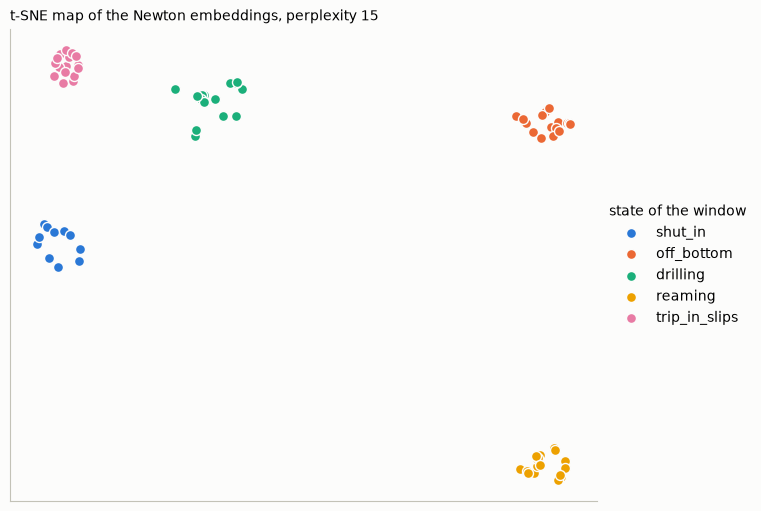

In [13]:
from sklearn.manifold import TSNE

def project(vectors, perplexity=15):
    """Place every window on a 2-D map with t-SNE, so that windows with similar vectors land near each other.
    perplexity: roughly how many neighbours each window tries to keep close. Returns the map positions as [windows x 2]."""
    return TSNE(n_components=2, perplexity=perplexity, init="pca", random_state=0).fit_transform(vectors)     # random_state: the same map on every run

def draw_map(points, title=""):
    """One dot per window, coloured by its state. points: [windows x 2]."""
    fig, ax = plt.subplots(figsize=(7.5, 5), layout="constrained")
    for s, colour in STATE_COLORS.items():
        ax.scatter(*points[window_state == s].T, s=52, color=colour, edgecolor="#fcfcfb", linewidth=1, label=s)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)                    # the positions have no unit: only which dots are near which matters
    ax.set_title(title, loc="left", fontsize=10)
    ax.legend(frameon=False, title="state of the window", loc="center left", bbox_to_anchor=(1, 0.5)); plt.show()

points = project(vectors)
print("map positions:", points.shape, "= [windows x 2]")
draw_map(points, "t-SNE map of the Newton embeddings, perplexity 15")

**Checkpoint.** You should see five separate groups of dots, one per state, with every dot in the group of its own colour. Newton was never told the states: it saw only the sensor readings, and the colours are added from the rig's log when the dots are drawn. Windows of one state end up together because their Newton embeddings are alike. The two `drilling` stretches, far apart in the recording, fall into a single group.

### Exercise 4.1: what can you trust on this map?

Draw the map again with the perplexity at 5 and at 30, and compare the three maps. Look for what stays the same and what changes.

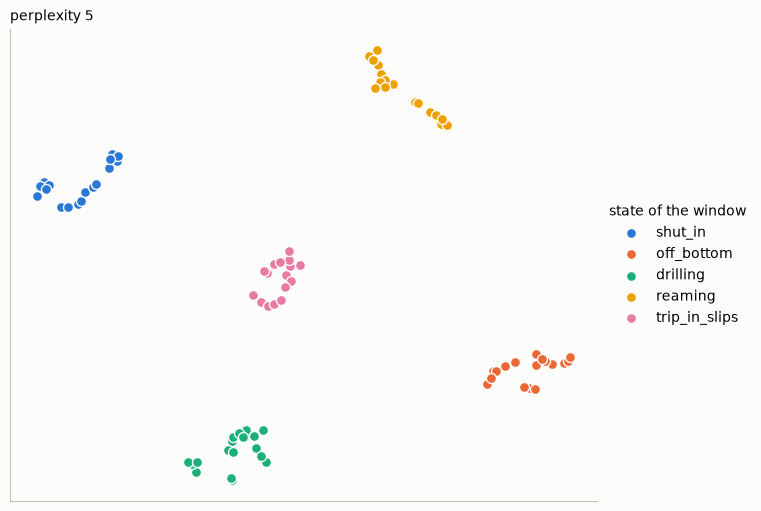

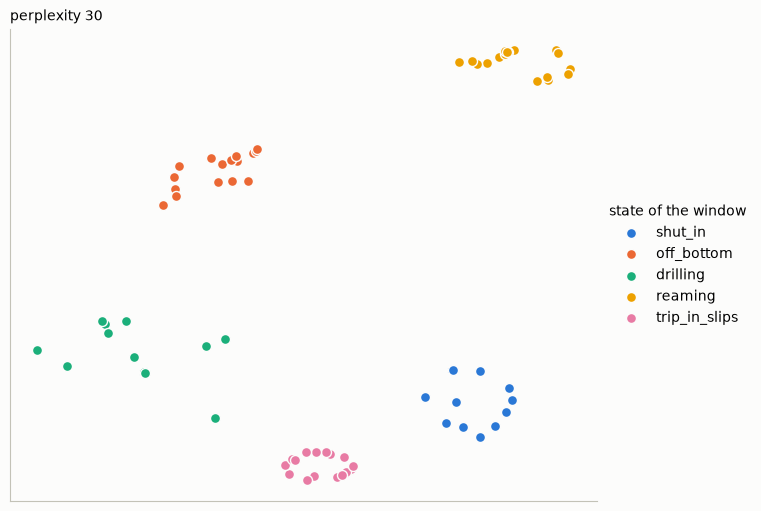

In [14]:
for perplexity in (5, 30):
    draw_map(project(vectors, perplexity), f"perplexity {perplexity}")

**Checkpoint.** The five groups are there every time, and each holds the same windows: that is the part of the map you can trust. Everything else changes from one map to the next: where a group sits, which groups are its neighbours, how round or stretched it is, how tightly its dots are packed.

At perplexity 30 the groups are looser, and one `drilling` dot sits nearer the `trip_in_slips` group than its own. It is the last `drilling` window, a mixed window from Lab 1: it runs across the change of state, and a quarter of its readings already belong to `trip_in_slips`.

Read a t-SNE map for which windows are together, and not for distances or shapes.

## 7. Lab 5: name the state from a few examples

So far, every window's state has come from the rig's log. On your own equipment you will rarely have that: someone has to say what the machine was doing, and nobody does it for every window. What you can usually get is a handful of moments where the state is known.

That is enough to build a classifier. Take a few windows of each state as labelled **examples**. To name any other window, find the example whose Newton embedding is most similar to it, and give the window that example's state. Nothing is trained, so adding a state means adding a few examples of it.

The cell below picks 3 examples of each state at random, names every other window, and compares the names with the rig's log.

In [15]:
def pick_examples(per_state, seed=0):
    """Pick `per_state` windows of each state at random to be the labelled examples. Mixed windows are never picked."""
    rng = np.random.default_rng(seed)                                               # the same seed picks the same examples on every run
    clean = np.array([len(set(state[s:s + WINDOW])) == 1 for s in window_start])    # True where all of a window's readings have one state
    return np.concatenate([rng.choice(np.flatnonzero((window_state == s) & clean), per_state, replace=False) for s in STATE_COLORS])

def classify(vectors, examples):
    """Name every window after its most similar example. Returns one state per window."""
    similarity = vectors @ vectors[examples].T                # [windows x examples]: every window against every example
    return window_state[examples][similarity.argmax(axis=1)]

def accuracy(named, examples):
    """The share of windows named correctly. The examples themselves are left out: the classifier was given their states."""
    rest = np.setdiff1d(np.arange(len(named)), examples)
    return (named[rest] == window_state[rest]).mean()

examples = pick_examples(3)
named = classify(vectors, examples)
print(f"{len(examples)} examples, {len(vectors) - len(examples)} windows to name: accuracy {accuracy(named, examples):.2f}")

# Logged state against named state, for the windows that were not examples.
rest = np.setdiff1d(np.arange(len(vectors)), examples)
pd.crosstab(pd.Series(window_state[rest], name="logged state"), pd.Series(named[rest], name="named by the classifier"))

15 examples, 70 windows to name: accuracy 1.00


named by the classifier,drilling,off_bottom,reaming,shut_in,trip_in_slips
logged state,,,,,
drilling,15,0,0,0,0
off_bottom,0,14,0,0,0
reaming,0,0,14,0,0
shut_in,0,0,0,14,0
trip_in_slips,0,0,0,0,13


**Checkpoint.** 15 examples name the other 70 windows, and the accuracy should be 1.00, or 0.99 if one window is named wrongly. In the table, the windows sit on the diagonal, where the logged state and the named state agree. The classifier was given the states of 15 windows. The log was needed for the other 70 only to check its answers.

The next cell shows where the examples lie on the map from Lab 4. Underneath the map it draws a timeline of the whole recording, twice: once with the state the rig logged for each window, and once with the state the classifier named.

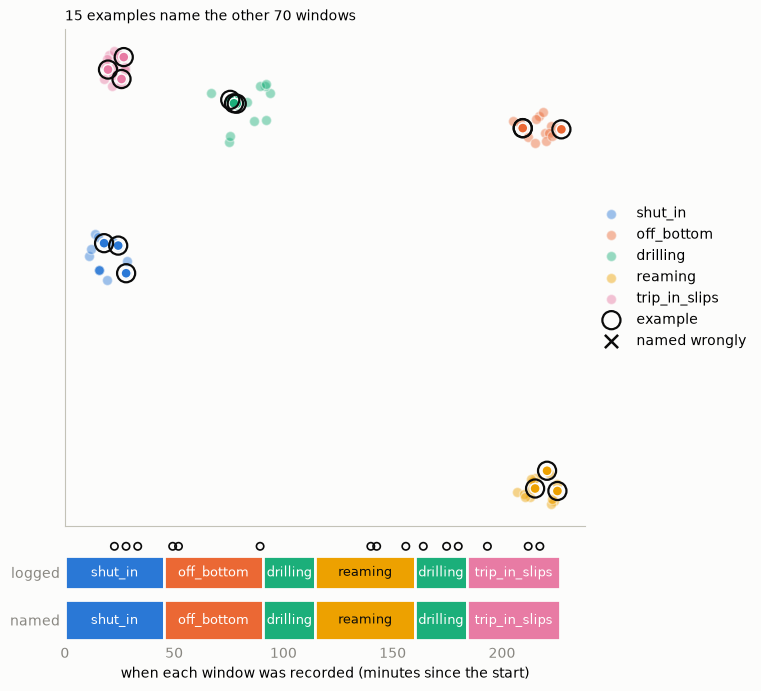

In [16]:
# The Lab 4 map again, with a timeline underneath. A ring marks an example; a cross marks a window that was named wrongly.
fig, (ax, logged, by_classifier) = plt.subplots(3, 1, figsize=(7.5, 6.8), height_ratios=[1, 0.11, 0.09], layout="constrained")
for s, colour in STATE_COLORS.items():
    ax.scatter(*points[window_state == s].T, s=52, color=colour, edgecolor="#fcfcfb", linewidth=1, alpha=0.45, label=s)
ax.scatter(*points[examples].T, s=52, c=[STATE_COLORS[s] for s in window_state[examples]], edgecolor="#fcfcfb", linewidth=1)
ax.scatter(*points[examples].T, s=170, facecolors="none", edgecolor="#0b0b0b", linewidth=1.6, label="example")
wrong = rest[named[rest] != window_state[rest]]
ax.scatter(*points[wrong].T, s=90, marker="x", color="#0b0b0b", linewidth=1.8, label="named wrongly")
ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
ax.set_title(f"{len(examples)} examples name the other {len(rest)} windows", loc="left", fontsize=10)
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1, 0.5))

# The timeline: the whole recording twice, in the order it was recorded.
# Top strip: the state the rig logged for each window. Bottom strip: the state the classifier named.
at = minutes[window_start]                                    # the minute each window starts at
middle = at + (at[1] - at[0]) / 2                             # the middle of each window, where its ring or cross is drawn
draw_states(logged, window_state, at, "logged")
draw_states(by_classifier, named, at, "named")
logged.scatter(middle[examples], np.full(len(examples), 0.62), s=28, facecolors="none", edgecolor="#0b0b0b", linewidth=1.2)
by_classifier.scatter(middle[wrong], np.zeros(len(wrong)), s=45, marker="x", color="#0b0b0b", linewidth=1.6)
logged.set_ylim(-0.4, 0.9); logged.tick_params(labelbottom=False); logged.set_xlim(by_classifier.get_xlim())
by_classifier.set_xlabel("when each window was recorded (minutes since the start)"); plt.show()

**Checkpoint.** Each group on the map holds its three ringed examples. The ringed dots are all the classifier knows, and that is why it works: a window's most similar example is one from its own group. A cross marks a window named wrongly; you should see none, or one.

The timeline underneath is what the whole workshop has been building. The top strip is the state the rig logged, and the small rings above it show when the 15 examples were recorded. The bottom strip is the state the classifier named, window by window. The two strips should match, or differ in one window, which then carries a cross. From 15 labelled windows and the sensor readings, the classifier has rebuilt the rig's log for the entire recording.

### Exercise 5.1: how few examples are enough?

The examples are picked at random, so a single run says little. Repeat the experiment with 1, 2, 3 and 5 examples per state, with 20 different picks each, and look at the average accuracy and at the worst.

In [17]:
for per_state in (1, 2, 3, 5):
    scores = []
    for seed in range(20):
        picked = pick_examples(per_state, seed)
        scores.append(accuracy(classify(vectors, picked), picked))
    print(f"{per_state} per state: average accuracy {np.mean(scores):.3f}, worst of 20 picks {np.min(scores):.3f}")

1 per state: average accuracy 0.977, worst of 20 picks 0.875
2 per state: average accuracy 0.993, worst of 20 picks 0.973
3 per state: average accuracy 0.998, worst of 20 picks 0.986
5 per state: average accuracy 0.998, worst of 20 picks 0.983


**Checkpoint.** One example per state already names about 98% of the windows on average, but it depends on the pick: the worst of the 20 draws scores about 0.88, because a single window can be an untypical one. With three examples per state the worst draw is about 0.99, and five add nothing more. A few examples per state are enough; one is a gamble.